In [2]:
#202432082_MutiaraAzizi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import MinMaxScaler

Jumlah baris dan kolom: (10114, 7)
        Date     USD     EUR     GBP      INR      AED    CNY
0 1985-01-01  308.30  402.45  266.01  3825.85  1134.42    NaN
1 1985-01-02  305.50  401.49  266.00  3787.05  1134.42    NaN
2 1985-01-03  302.30  397.08  262.76  3718.88  1107.67    NaN
3 1985-01-04  303.15  397.15  262.58  3759.64  1118.21    NaN
4 1985-01-07  298.25  392.55  261.17  3741.23  1091.58  835.8
Date    datetime64[ns]
USD            float64
EUR            float64
GBP            float64
INR            float64
AED            float64
CNY            float64
dtype: object
Date    0
USD     0
EUR     0
GBP     0
INR     0
AED     0
CNY     4
dtype: int64


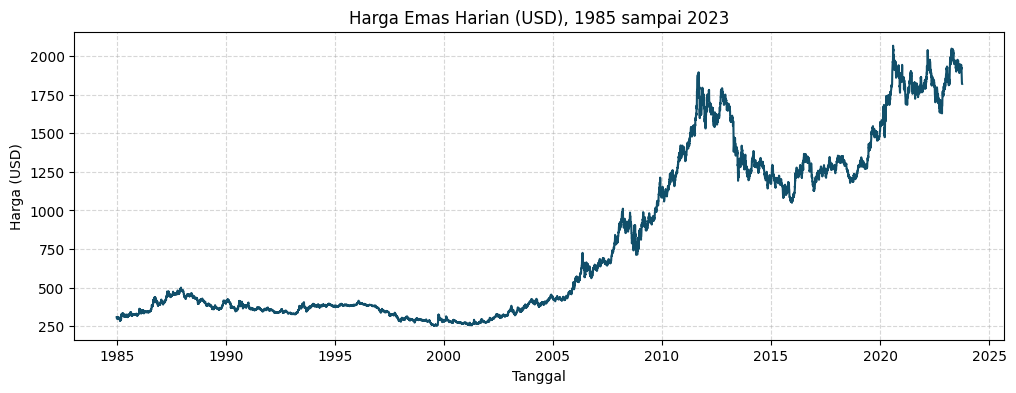

In [3]:
#202432082_MutiaraAzizi
# Baca file CSV dan ubah kolom Date menjadi format tanggal
df = pd.read_csv('daily_gold_rate.csv')
df['Date'] = pd.to_datetime(df['Date'])

# Tampilkan ukuran data, 5 baris awal, tipe data, dan jumlah nilai kosong
print('Jumlah baris dan kolom:', df.shape)
print(df.head())
print(df.dtypes)
print(df.isna().sum())

# Grafik harga emas (USD) dari waktu ke waktu
plt.figure(figsize=(12, 4))
plt.plot(df['Date'], df['USD'], color='#114F6A')
plt.title('Harga Emas Harian (USD), 1985 sampai 2023')
plt.xlabel('Tanggal')
plt.ylabel('Harga (USD)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [4]:
#202432082_MutiaraAzizi
# Ambil kolom USD sebagai target, bentuknya (jumlah_baris, 1)
data = df[['USD']].values

# Bagi data 80% latih dan 20% uji, urutan waktu tidak diacak
split = int(len(data) * 0.8)
train_data = data[:split]
test_data = data[split:]

# Normalisasi ke rentang 0 sampai 1, scaler hanya belajar dari data latih
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_data)
test_scaled = scaler.transform(test_data)

# Sliding window: 30 hari terakhir jadi input, hari ke-31 jadi target
def create_sequences(data, window):
    X, y = [], []
    for i in range(len(data) - window):
        X.append(data[i:i + window])
        y.append(data[i + window])
    return np.array(X), np.array(y)

window = 30
X_train, y_train = create_sequences(train_scaled, window)
X_test, y_test = create_sequences(test_scaled, window)

# Ubah ke tensor PyTorch bertipe float32
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

torch.Size([8061, 30, 1]) torch.Size([8061, 1]) torch.Size([1993, 30, 1]) torch.Size([1993, 1])


In [5]:
#202432082_MutiaraAzizi
class SequenceModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2):
        super(SequenceModel, self).__init__()
        # Lapisan LSTM: 1 fitur input, 64 unit tersembunyi, 2 lapis, dropout 20%
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers,
                            batch_first=True, dropout=0.2)
        # Lapisan linear mengubah 64 nilai menjadi 1 prediksi harga
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)        # out berukuran (batch, 30, 64)
        out = out[:, -1, :]          # ambil hasil langkah waktu terakhir
        return self.fc(out)          # prediksi berukuran (batch, 1)

In [6]:
#202432082_MutiaraAzizi
# Hyperparameter
epochs = 50
learning_rate = 0.001
batch_size = 64

# Pakai GPU kalau ada, kalau tidak pakai CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Objek model, fungsi loss, dan optimizer
model = SequenceModel().to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# DataLoader memecah data latih menjadi batch kecil
train_loader = DataLoader(TensorDataset(X_train, y_train),
                          batch_size=batch_size, shuffle=True)

# Daftar untuk menyimpan loss tiap epoch
train_losses = []

# Loop training
for epoch in range(epochs):
    model.train()
    total_loss = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()            # kosongkan gradien lama
        pred = model(xb)                 # forward pass
        loss = criterion(pred, yb)       # hitung MSE
        loss.backward()                  # backpropagation
        optimizer.step()                 # perbarui bobot
        total_loss += loss.item() * xb.size(0)
    epoch_loss = total_loss / len(train_loader.dataset)
    train_losses.append(epoch_loss)
    if (epoch + 1) % 5 == 0:
        print(f'Epoch {epoch+1}/{epochs}, Loss: {epoch_loss:.6f}')

Epoch 5/50, Loss: 0.000294
Epoch 10/50, Loss: 0.000237
Epoch 15/50, Loss: 0.000185
Epoch 20/50, Loss: 0.000205
Epoch 25/50, Loss: 0.000182
Epoch 30/50, Loss: 0.000156
Epoch 35/50, Loss: 0.000153
Epoch 40/50, Loss: 0.000132
Epoch 45/50, Loss: 0.000123
Epoch 50/50, Loss: 0.000117


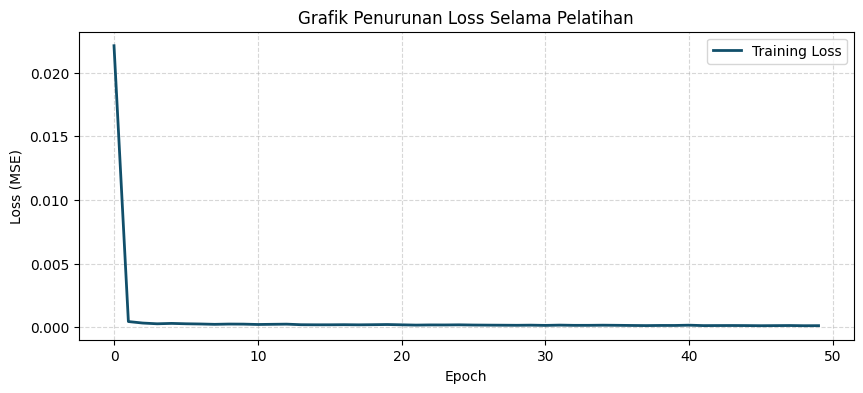

In [7]:
#202432082_MutiaraAzizi
plt.figure(figsize=(10, 4))
plt.plot(train_losses, color='#114F6A', linewidth=2, label='Training Loss')
plt.title('Grafik Penurunan Loss Selama Pelatihan')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

RMSE: 34.49 | MAE: 24.98 | MAPE: 1.48%


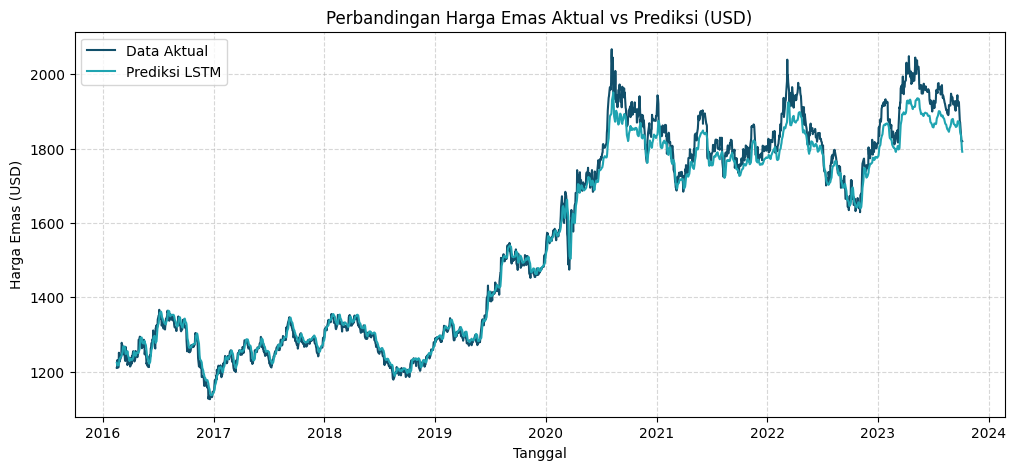

In [8]:
#202432082_MutiaraAzizi
# Prediksi pada data uji
model.eval()
with torch.no_grad():
    pred = model(X_test.to(device)).cpu().numpy()

# Kembalikan skala ke harga asli (USD)
pred_inv = scaler.inverse_transform(pred)
actual_inv = scaler.inverse_transform(y_test.numpy())

# Metrik evaluasi
rmse = np.sqrt(np.mean((pred_inv - actual_inv) ** 2))
mae = np.mean(np.abs(pred_inv - actual_inv))
mape = np.mean(np.abs((actual_inv - pred_inv) / actual_inv)) * 100
print(f'RMSE: {rmse:.2f} | MAE: {mae:.2f} | MAPE: {mape:.2f}%')

# Grafik aktual vs prediksi
test_dates = df['Date'].values[split + window:]
plt.figure(figsize=(12, 5))
plt.plot(test_dates, actual_inv, color='#114F6A', label='Data Aktual')
plt.plot(test_dates, pred_inv, color='#1FA4B1', label='Prediksi LSTM')
plt.title('Perbandingan Harga Emas Aktual vs Prediksi (USD)')
plt.xlabel('Tanggal')
plt.ylabel('Harga Emas (USD)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()